Float baseline jet tagger. 16→64→32→32→5 MLP trained on the hls4ml LHC jet dataset (OpenML 42468). Test accuracy: 77.1%. This is the floating-point reference for the quantized FPGA models.

Cell 1: Conneting to Google Drive-


In [1]:
import os
from google.colab import drive
drive.mount('/content/drive')

OUT = '/content/drive/MyDrive/basys3-l1-trigger/ml'
os.makedirs(OUT, exist_ok=True)
SEED = 42

Mounted at /content/drive


Cell 2: Data Preparation

In [3]:
from sklearn.datasets import fetch_openml

data = fetch_openml(
    name=None,
    version='active',
    data_id=42468,
    target_column='default-target',
    cache=True,
    return_X_y=False,
    as_frame='auto'
)


X boyutu: (830000, 16)
y boyutu: (830000,)
Öznitelikler: ['zlogz', 'c1_b0_mmdt', 'c1_b1_mmdt', 'c1_b2_mmdt', 'c2_b1_mmdt', 'c2_b2_mmdt', 'd2_b1_mmdt', 'd2_b2_mmdt', 'd2_a1_b1_mmdt', 'd2_a1_b2_mmdt', 'm2_b1_mmdt', 'm2_b2_mmdt', 'n2_b1_mmdt', 'n2_b2_mmdt', 'mass_mmdt', 'multiplicity']


,zlogz,c1_b0_mmdt,c1_b1_mmdt,c1_b2_mmdt,c2_b1_mmdt,c2_b2_mmdt,d2_b1_mmdt,d2_b2_mmdt,d2_a1_b1_mmdt,d2_a1_b2_mmdt,m2_b1_mmdt,m2_b2_mmdt,n2_b1_mmdt,n2_b2_mmdt,mass_mmdt,multiplicity
0,-2.935125,0.383155,0.005126,0.000084,0.009070,0.000179,1.769445,2.123898,1.769445,0.308185,0.135687,0.083278,0.412136,0.299058,8.926882,75.0
1,-1.927335,0.270699,0.001585,0.000011,0.003232,0.000029,2.038834,2.563099,2.038834,0.211886,0.063729,0.036310,0.310217,0.226661,3.886512,31.0
2,-3.112147,0.458171,0.097914,0.028588,0.124278,0.038487,1.269254,1.346238,1.269254,0.246488,0.115636,0.079094,0.357559,0.289220,162.144669,61.0
3,-2.666515,0.437068,0.049122,0.007978,0.047477,0.004802,0.966505,0.601864,0.966505,0.160756,0.082196,0.033311,0.238871,0.094516,91.258934,39.0
4,-2.484843,0.428981,0.041786,0.006110,0.023066,0.001123,0.552002,0.183821,0.552002,0.084338,0.048006,0.014450,0.141906,0.036665,79.725777,35.0


class
t    167851
g    167125
w    167083
z    166875
q    161066
Name: count, dtype: int64


,mean,std,min,max
zlogz,-2.865343,0.580389,-4.759511e+00,-0.438996
c1_b0_mmdt,0.433322,0.055448,9.110353e-02,0.493779
c1_b1_mmdt,0.037766,0.029154,7.342856e-05,0.165237
c1_b2_mmdt,0.007995,0.009403,4.472011e-08,0.071227
c2_b1_mmdt,0.045608,0.038657,2.499823e-06,0.219034
c2_b2_mmdt,0.007609,0.012174,1.472518e-10,0.107914
d2_b1_mmdt,1.295784,0.458041,5.866442e-03,3.968144
d2_b2_mmdt,1.083618,0.730066,1.561585e-04,6.408456
d2_a1_b1_mmdt,1.295784,0.458041,5.866442e-03,3.968144
d2_a1_b2_mmdt,0.190380,0.075417,2.127614e-04,0.366573


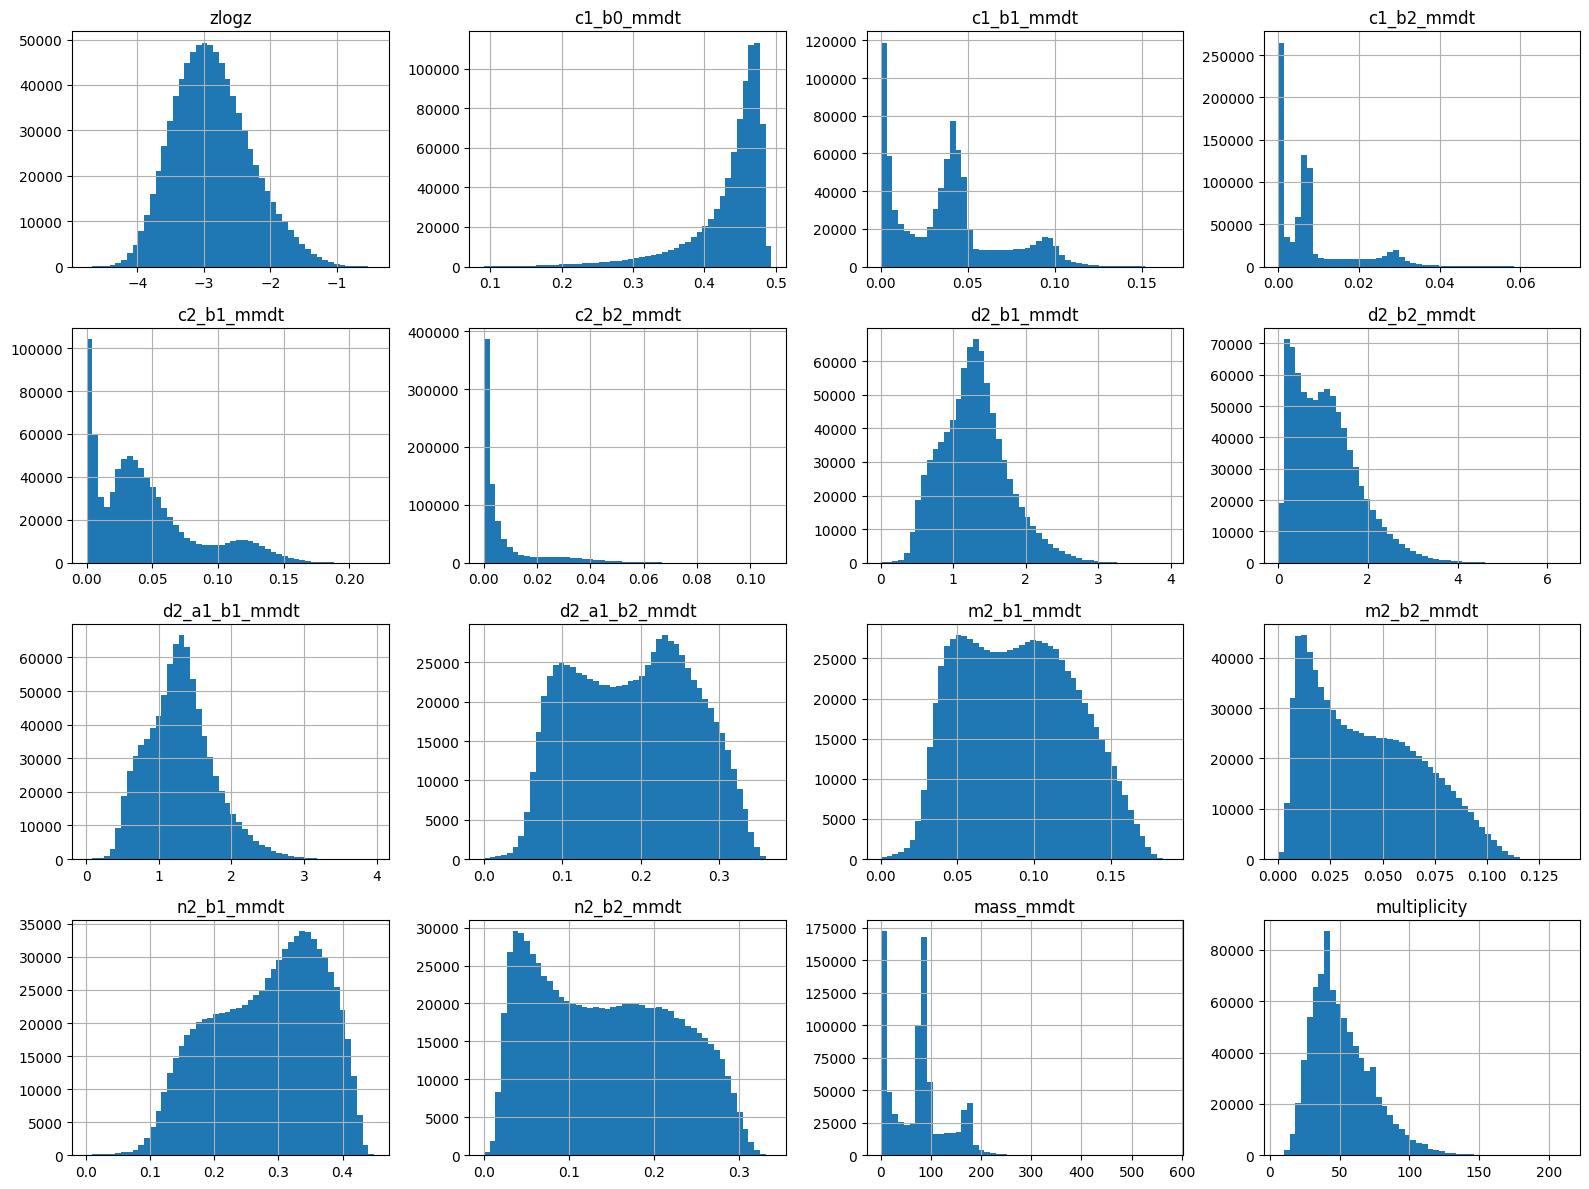

Etiket tipi: category
İlk 10 etiket: ['g', 'w', 't', 'z', 'w', 'w', 't', 'g', 'z', 'g']


In [4]:
import matplotlib.pyplot as plt

# Öznitelikler ve etiketler
X = data.data      # pandas DataFrame
y = data.target    # pandas Series

# 1. Boyutlar ve öznitelik isimleri
print("X boyutu:", X.shape)
print("y boyutu:", y.shape)
print("Öznitelikler:", list(X.columns))
display(X.head())

# 2. Sınıf dağılımı
print(y.value_counts())

# 3. Değer aralıkları
display(X.describe().T[["mean", "std", "min", "max"]])

X.hist(bins=50, figsize=(16, 12))
plt.tight_layout()
plt.show()

# 4. Etiket formatı
print("Etiket tipi:", y.dtype)
print("İlk 10 etiket:", y.head(10).tolist())

In [5]:
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

X = data.data.to_numpy(dtype=np.float32)
le = LabelEncoder()
y_int = le.fit_transform(data.target)
y = to_categorical(y_int, num_classes=5)
print("Sınıf sırası:", list(le.classes_))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y_int
)

scaler = StandardScaler().fit(X_train)          # sadece eğitim verisinden!
X_train_s = scaler.transform(X_train).astype(np.float32)
X_test_s  = scaler.transform(X_test).astype(np.float32)

np.savez(f'{OUT}/scaler.npz', mean=scaler.mean_, scale=scaler.scale_,
         classes=le.classes_, feature_names=np.array(data.feature_names))
print("Eğitim:", X_train_s.shape, " Test:", X_test_s.shape)

Sınıf sırası: ['g', 'q', 't', 'w', 'z']
Eğitim: (664000, 16)  Test: (166000, 16)


Cell 3: Referance Model and Train


In [6]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

tf.keras.utils.set_random_seed(SEED)

model = models.Sequential([
    layers.Input(shape=(16,)),
    layers.Dense(64, activation='relu', name='fc1'),
    layers.Dense(32, activation='relu', name='fc2'),
    layers.Dense(32, activation='relu', name='fc3'),
    layers.Dense(5, activation='softmax', name='output'),
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

cbs = [
    callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5),
    callbacks.ModelCheckpoint(f'{OUT}/baseline_float.keras', save_best_only=True),
]

history = model.fit(X_train_s, y_train, validation_split=0.25,
                    epochs=100, batch_size=1024, callbacks=cbs, verbose=2)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ fc1 (Dense)                     │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc3 (Dense)                     │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,389 (17.14 KB)

 Trainable params: 4,389 (17.14 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
487/487 - 8s - 16ms/step - accuracy: 0.6894 - loss: 0.8749 - val_accuracy: 0.7375 - val_loss: 0.7488 - learning_rate: 0.0010
Epoch 2/100
487/487 - 2s - 4ms/step - accuracy: 0.7428 - loss: 0.7277 - val_accuracy: 0.7493 - val_loss: 0.7091 - learning_rate: 0.0010
Epoch 3/100
487/487 - 2s - 4ms/step - accuracy: 0.7508 - loss: 0.7023 - val_accuracy: 0.7539 - val_loss: 0.6928 - learning_rate: 0.0010
Epoch 4/100
487/487 - 2s - 5ms/step - accuracy: 0.7545 - loss: 0.6890 - val_accuracy: 0.7562 - val_loss: 0.6828 - learning_rate: 0.0010
Epoch 5/100
487/487 - 5s - 10ms/step - accuracy: 0.7569 - loss: 0.6797 - val_accuracy: 0.7583 - val_loss: 0.6764 - learning_rate: 0.0010
Epoch 6/100
487/487 - 5s - 9ms/step - accuracy: 0.7588 - loss: 0.6741 - val_accuracy: 0.7598 - val_loss: 0.6716 - learning_rate: 0.0010
Epoch 7/100
487/487 - 4s - 8ms/step - accuracy: 0.7598 - loss: 0.6704 - val_accuracy: 0.7608 - val_loss: 0.6679 - learning_rate: 0.0010
Epoch 8/100
487/487 - 3s - 6ms/step - accuracy

Cell 4: Test


41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Test doğruluğu: 0.7713
  AUC g: 0.9436
  AUC q: 0.9088
  AUC t: 0.9657
  AUC w: 0.9552
  AUC z: 0.9512


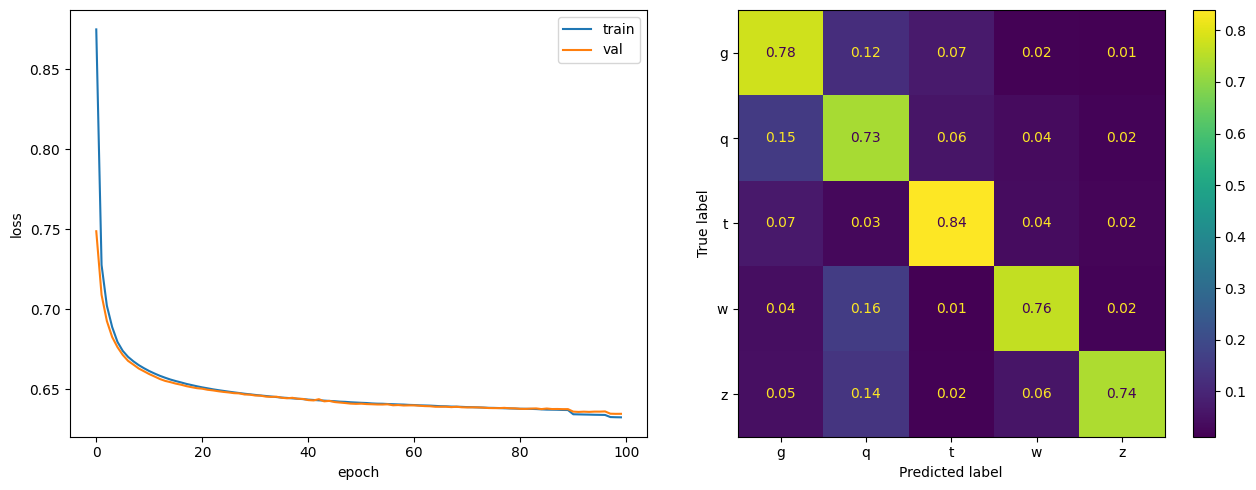

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, roc_auc_score, ConfusionMatrixDisplay

y_pred = model.predict(X_test_s, batch_size=4096)
acc = accuracy_score(y_test.argmax(1), y_pred.argmax(1))
aucs = roc_auc_score(y_test, y_pred, average=None)

print(f"Test doğruluğu: {acc:.4f}")
for c, a in zip(le.classes_, aucs):
    print(f"  AUC {c}: {a:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(history.history['loss'], label='train')
ax[0].plot(history.history['val_loss'], label='val')
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('loss'); ax[0].legend()
ConfusionMatrixDisplay.from_predictions(
    y_test.argmax(1), y_pred.argmax(1), display_labels=le.classes_,
    normalize='true', values_format='.2f', ax=ax[1])
plt.tight_layout()
plt.savefig(f'{OUT}/baseline_float.png', dpi=150)
plt.show()

In [15]:
data.data['d2_b1_mmdt']

,d2_b1_mmdt
0,1.769445
1,2.038834
2,1.269254
3,0.966505
4,0.552002
...,...
829995,1.319914
829996,0.508506
829997,1.301970
829998,1.061160
